# Projet Machine Learning - Clustering des profils socio-professionnels

**Variable étudiée** : `marital-status` (situation matrimoniale).

**Objectif métier** : segmenter la population en profils socio-professionnels homogènes (clients d'une banque ou d'une assurance, par exemple) afin d'adapter les offres : crédit immobilier, assurance famille, épargne jeunes... On étudie en particulier si ces profils, construits **sans connaître la situation matrimoniale**, la retrouvent quand même. Si oui, on peut la deviner pour les clients qui ne la déclarent pas.

**Objectif data science** : apprentissage **non supervisé** (clustering). Méthode principale : K-Means, comparée à une Classification Ascendante Hiérarchique (CAH, méthode de Ward).

**Rôle de la variable étudiée** : en clustering il n'y a pas de cible. `marital-status` est donc **exclue** des variables utilisées pour former les clusters, puis sert *après coup* à valider et interpréter les groupes (NMI, ARI, pureté, tableau croisé).

**Dataset** : Adult (Census Income) - UCI

## Importer les bibliothèques nécessaires

In [1]:
# --- Outils pour manipuler les données ---
import pandas as pd            # pandas : pour lire et manipuler les tableaux de données
import numpy as np             # numpy : pour les calculs sur les nombres

# --- Outils pour dessiner les graphiques ---
import matplotlib.pyplot as plt   # matplotlib : pour tracer les graphiques
import seaborn as sns             # seaborn : des graphiques plus jolis (heatmap, boxplot...)

# --- Outils de machine learning (scikit-learn) ---
from sklearn.preprocessing import OneHotEncoder, StandardScaler   # préparer les données
from sklearn.compose import ColumnTransformer                     # appliquer des transformations différentes selon les colonnes
from sklearn.cluster import KMeans                                # l'algorithme de clustering K-Means
from sklearn.decomposition import PCA                             # ACP : pour dessiner les données en 2D
from sklearn.metrics import (silhouette_score, davies_bouldin_score,           # mesurer la qualité des clusters
                             normalized_mutual_info_score, adjusted_rand_score)  # comparer deux découpages
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster  # outils de la CAH

# Réglages d'affichage : montrer toutes les colonnes et choisir le style des graphiques
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Une couleur fixe par cluster : le cluster 0 aura toujours la même couleur sur tous les graphiques
COULEURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6', '#e34948', '#008300']
# Couleurs différentes pour la situation matrimoniale, pour ne pas les confondre avec celles des clusters
COULEURS_MS = ['#6250d6', '#e87ba4', '#eda100']

# Graine du hasard : avec 42, on retrouve exactement les mêmes résultats à chaque exécution
RS = 42

## Charger le dataset Adult

In [2]:
# Le fichier adult.data n'a pas de ligne d'en-tête, donc on donne nous-mêmes le nom de chaque colonne
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship', 'race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
           'income']

# On lit le fichier. na_values='?' : les '?' du fichier sont des valeurs manquantes (NaN)
# skipinitialspace=True : on enlève les espaces qui traînent après les virgules
df = pd.read_csv("adult.data", names=columns, na_values='?', skipinitialspace=True)

# On affiche la taille du tableau : nombre de lignes (personnes) et de colonnes (variables)
print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")

Dimensions : 32561 lignes x 15 colonnes


## Exploration et aperçu des données

In [3]:
# Les 5 premières lignes, pour voir à quoi ressemblent les données
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
# Statistiques de chaque colonne : moyenne, min, max pour les nombres ; valeur la plus fréquente pour les textes
df.describe(include='all')

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [5]:
# Nombre de valeurs manquantes dans chaque colonne
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64

**Distribution de la variable étudiée `marital-status`**

marital-status
Married-civ-spouse       0.460
Never-married            0.328
Divorced                 0.136
Separated                0.031
Widowed                  0.030
Married-spouse-absent    0.013
Married-AF-spouse        0.001
Name: proportion, dtype: float64


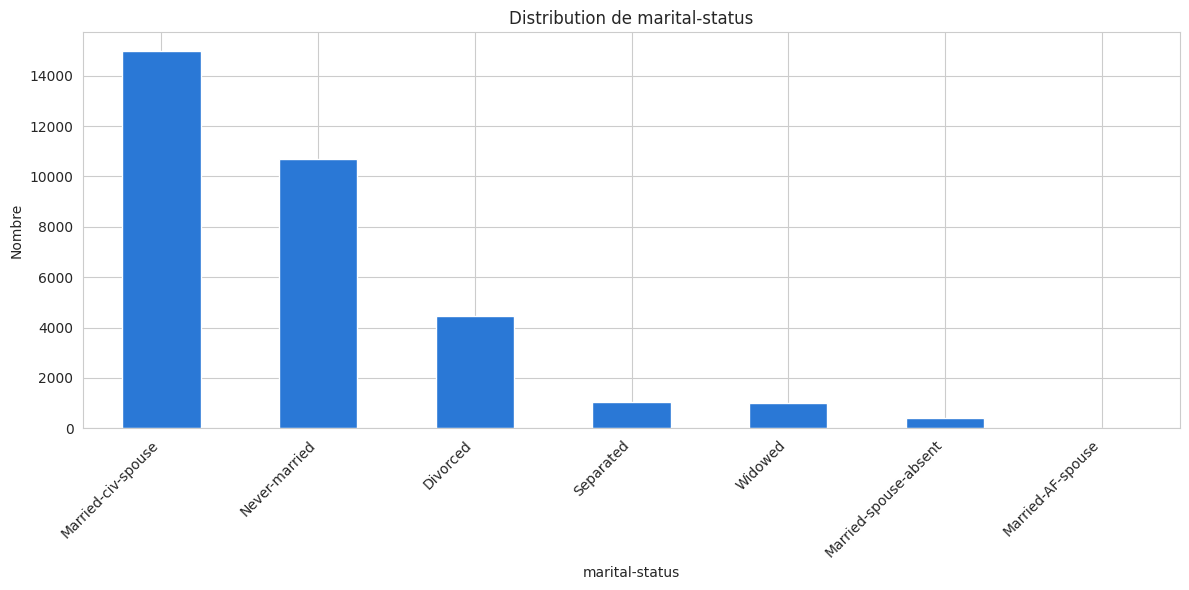

In [6]:
# Part de chaque situation matrimoniale dans la population (en proportion)
print(df['marital-status'].value_counts(normalize=True).round(3))

# Même information sous forme de diagramme en barres
df['marital-status'].value_counts().plot(kind='bar', color=COULEURS[0])
plt.title("Distribution de marital-status")
plt.xlabel("marital-status")
plt.ylabel("Nombre")
plt.xticks(rotation=45, ha='right')   # on incline les noms pour qu'ils restent lisibles
plt.tight_layout()
plt.show()

Trois situations dominent : **Married-civ-spouse** (~46 %), **Never-married** (~33 %) et **Divorced** (~14 %). Les autres sont rares. Ce déséquilibre est à garder en tête : une pureté de cluster doit être comparée à la part de la classe majoritaire (~46 %), pas à 100 %.

# Partie 1 : Nettoyage des données

### Gestion des doublons

In [7]:
# On compte les lignes qui apparaissent deux fois (ou plus) : ce sont des doublons
print("Nombre de doublons avant :", df.duplicated().sum())

# On supprime les doublons : une personne ne doit être comptée qu'une seule fois
df.drop_duplicates(inplace=True)

# On renumérote les lignes de 0 à n-1 pour avoir un tableau propre
df.reset_index(drop=True, inplace=True)

# Vérification : il doit rester 0 doublon
print("Nombre de doublons après  :", df.duplicated().sum())

Nombre de doublons avant : 24
Nombre de doublons après  : 0


### Gestion des valeurs manquantes

Les `?` (devenus `NaN`) sont dans `workclass`, `occupation` et `native-country`. On les remplace par `"Unknown"` pour ne pas perdre de lignes.

In [8]:
# Dans ces 3 colonnes, on remplace les valeurs manquantes par "Unknown" (inconnu)
# Avantage : on garde toutes les personnes au lieu de supprimer des lignes
for col in ['workclass', 'occupation', 'native-country']:
    df[col] = df[col].fillna('Unknown')

# Vérification : il ne doit plus rester aucune valeur manquante
print("Valeurs manquantes après traitement :", df.isnull().sum().sum())

Valeurs manquantes après traitement : 0


### Variables non utilisées pour le clustering

| Variable | Raison |
|---|---|
| `marital-status` | **variable étudiée** : exclue pour pouvoir valider les clusters après coup |
| `relationship` | quasi-doublon de `marital-status` (Husband/Wife correspondent à Married). La garder rendrait le résultat trivial |
| `fnlwgt` | poids statistique du recensement, sans lien avec la personne |
| `education` | redondante avec `education-num` |
| `race`, `native-country` | très déséquilibrées et sensibles, inutiles pour un profil socio-professionnel |

Les variables retenues pour le clustering sont : `age`, `workclass`, `education-num`, `occupation`, `sex`, `hours-per-week`, `income`, `capital-gain`, `capital-loss`.

### Gestion des valeurs aberrantes (outliers)

Détection par la méthode IQR.

In [9]:
# Les 5 colonnes numériques à examiner
num_cols_all = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

print("Détection des outliers (méthode IQR) :\n")
for col in num_cols_all:
    # Q1 = valeur en dessous de laquelle se trouvent 25 % des personnes ; Q3 = idem pour 75 %
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    # IQR = écart entre Q3 et Q1 : c'est la largeur de la zone "normale"
    IQR = Q3 - Q1
    # Règle de l'IQR : une valeur trop loin de cette zone (plus de 1,5 x IQR) est un outlier
    bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[col] < bas) | (df[col] > haut)).sum()   # nombre de valeurs hors de la zone normale
    print(f"{col:16s} : Q1={Q1:6.0f}  Q3={Q3:6.0f}  -> {n} outliers")

Détection des outliers (méthode IQR) :

age              : Q1=    28  Q3=    48  -> 142 outliers
education-num    : Q1=     9  Q3=    12  -> 1193 outliers
capital-gain     : Q1=     0  Q3=     0  -> 2712 outliers
capital-loss     : Q1=     0  Q3=     0  -> 1519 outliers
hours-per-week   : Q1=    40  Q3=    45  -> 9002 outliers


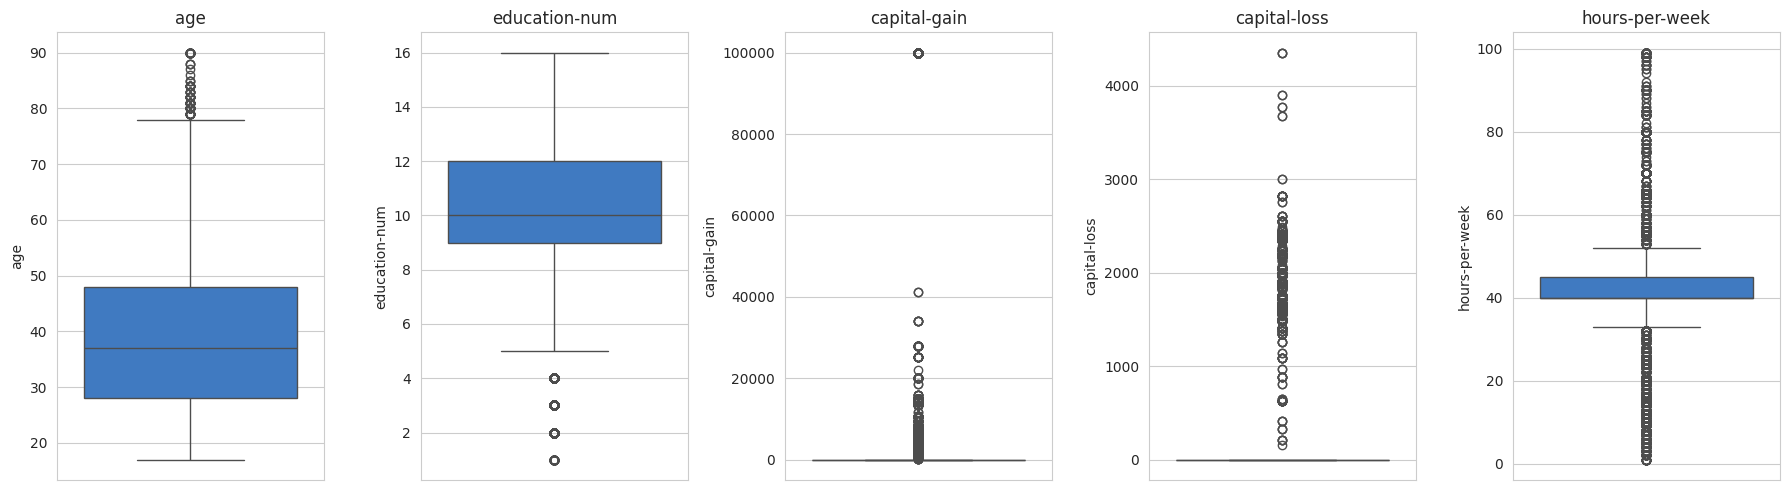

In [10]:
# Boxplot : la boîte montre la zone normale, les points au-dessus ou en dessous sont les valeurs extrêmes
fig, axes = plt.subplots(1, len(num_cols_all), figsize=(18, 5))
for i, col in enumerate(num_cols_all):
    sns.boxplot(y=df[col], ax=axes[i], color=COULEURS[0])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

Le K-Means est sensible aux valeurs extrêmes (il utilise des distances et des moyennes). Traitement choisi :

- `capital-gain` et `capital-loss` : plus de 90 % de zéros et quelques valeurs énormes (jusqu'à 99 999). On les remplace par deux **indicateurs binaires** (`has-capital-gain`, `has-capital-loss`). Un plafonnement IQR écraserait tout à 0 puisque Q1 = Q3 = 0.
- `age` et `hours-per-week` : plafonnement doux aux percentiles 1 % et 99 % (on ne supprime aucune ligne).
- `education-num` : on la garde telle quelle.

In [11]:
# Gains et pertes en capital : on ne garde que "oui / non" (1 = a un gain, 0 = n'en a pas)
# Raison : presque tout le monde a 0, et quelques valeurs énormes fausseraient les distances
df['has-capital-gain'] = (df['capital-gain'] > 0).astype(int)
df['has-capital-loss'] = (df['capital-loss'] > 0).astype(int)

# Âge et heures par semaine : on "coupe" les valeurs les plus extrêmes
# Tout ce qui est sous le 1er percentile devient la valeur du 1er percentile (idem pour le 99e en haut)
# On ne supprime aucune personne, on rapproche seulement les valeurs extrêmes
for col in ['age', 'hours-per-week']:
    bas, haut = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(lower=bas, upper=haut)

# Part de personnes qui ont un gain / une perte en capital
print(df[['has-capital-gain', 'has-capital-loss']].mean().round(3))
print()
# Vérification : le min et le max de l'âge et des heures après la coupure
print(df[['age', 'hours-per-week']].describe().loc[['min', 'max']])

has-capital-gain    0.083
has-capital-loss    0.047
dtype: float64

      age  hours-per-week
min  17.0             8.0
max  74.0            80.0


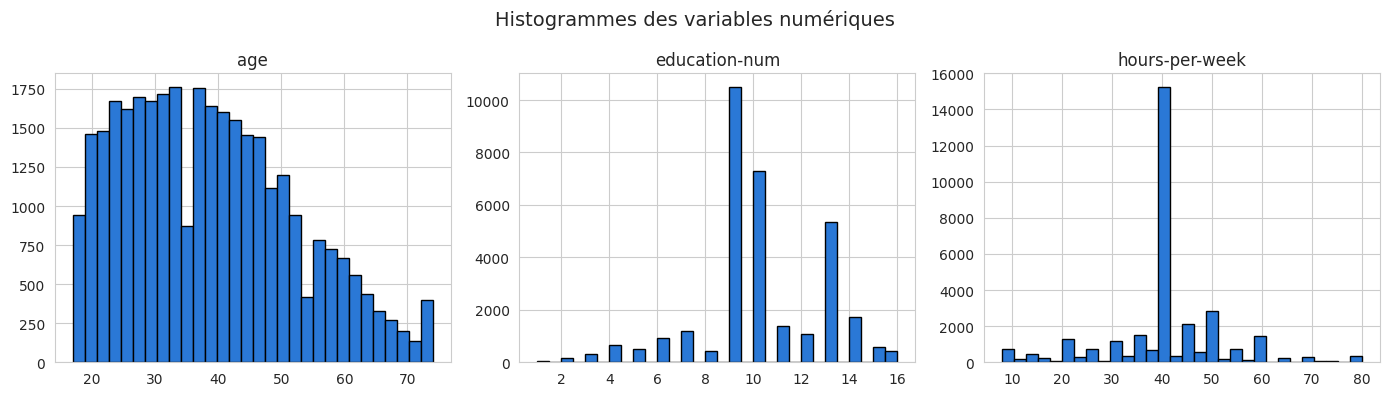

In [12]:
# Histogrammes : on regarde comment les valeurs sont réparties après nettoyage
df[['age', 'education-num', 'hours-per-week']].hist(figsize=(14, 4), bins=30, edgecolor='black', color=COULEURS[0], layout=(1, 3))
plt.suptitle("Histogrammes des variables numériques", fontsize=14)
plt.tight_layout()
plt.show()

# Partie 2 : Pourquoi `marital-status` ? (screening)

Pour choisir la variable étudiée sur des chiffres et pas au hasard, on teste plusieurs variables candidates. Pour chacune : on la retire des variables de clustering, on lance un K-Means (k = 5), puis on mesure à quel point les clusters la retrouvent avec la **NMI** (information mutuelle normalisée : 0 = aucun lien, 1 = clusters identiques à la variable).

On ne teste pas `income`, `relationship` et `hours-per-week` (déjà étudiées par d'autres groupes) ni `race` (trop déséquilibrée).

In [13]:
# Liste des variables qu'on utilise pour former les clusters
POOL = ['age', 'workclass', 'education-num', 'occupation', 'sex',
        'hours-per-week', 'income', 'has-capital-gain', 'has-capital-loss']
# Ces deux colonnes valent déjà 0 ou 1 : on ne les transforme pas
BINAIRES = ['has-capital-gain', 'has-capital-loss']

# Cette fonction prépare le tableau pour le K-Means. Elle fait trois choses :
#  1) standardise les colonnes numériques (même échelle pour toutes),
#  2) transforme les colonnes de texte en colonnes 0/1 (One-Hot),
#  3) laisse les colonnes binaires telles quelles.
def construire_matrice(features):
    sub = df[features]
    bin_c = [c for c in features if c in BINAIRES]                                      # colonnes déjà en 0/1
    num_c = [c for c in sub.select_dtypes(include=[np.number]).columns if c not in bin_c]  # vrais nombres (âge, heures...)
    cat_c = sub.select_dtypes(exclude=[np.number]).columns.tolist()                     # colonnes de texte (métier, workclass...)
    prep = ColumnTransformer([
        ('num', StandardScaler(), num_c),                           # nombres : moyenne 0 et écart-type 1
        ('cat', OneHotEncoder(sparse_output=False), cat_c),         # texte : une colonne 0/1 par catégorie
        ('bin', 'passthrough', bin_c),                              # binaires : inchangées
    ], verbose_feature_names_out=False)
    M = prep.fit_transform(sub)
    return M, prep.get_feature_names_out()

# Test : pour chaque variable candidate, on la retire des variables de clustering,
# on lance un K-Means, puis on regarde à quel point les clusters retrouvent cette variable (score NMI)
resultats = []
for v in ['marital-status', 'occupation', 'workclass', 'sex', 'age', 'education-num']:
    feats = [f for f in POOL if f != v]            # toutes les variables sauf la candidate
    M, _ = construire_matrice(feats)
    # Pour une variable numérique (âge, éducation), on la découpe en 4 groupes de même taille pour la comparer
    cible = df[v] if not pd.api.types.is_numeric_dtype(df[v]) else pd.qcut(df[v], 4, duplicates='drop').astype(str)
    # On répète 5 fois avec des graines différentes pour ne pas dépendre du hasard
    scores = [normalized_mutual_info_score(cible, KMeans(n_clusters=5, n_init=3, random_state=s).fit_predict(M))
              for s in range(5)]
    resultats.append((v, np.mean(scores), np.std(scores)))

# On classe les variables de la mieux retrouvée à la moins bien retrouvée
screening = (pd.DataFrame(resultats, columns=['variable étudiée', 'NMI moyenne', 'écart-type'])
             .sort_values('NMI moyenne', ascending=False).round(3).reset_index(drop=True))
screening

,variable étudiée,NMI moyenne,écart-type
0,marital-status,0.128,0.011
1,occupation,0.103,0.007
2,education-num,0.038,0.001
3,age,0.036,0.004
4,workclass,0.035,0.002
5,sex,0.020,0.002


**Lecture** : `marital-status` arrive en tête (NMI moyenne **0.128** sur 5 graines), devant `occupation` (0.103). L'écart est réel mais modeste : ces deux variables sont proches l'une de l'autre, et toutes deux bien au-dessus de `education-num`, `age`, `workclass` et `sex` (0.04 ou moins). `marital-status` est donc une dimension qui structure vraiment la population, ce qui en fait une bonne variable pour valider un clustering. Les NMI absolues restent faibles : aucune variable n'est fidèlement retrouvée.


# Partie 3 : Préparation pour le clustering

En apprentissage non supervisé il n'y a **pas de séparation train/test** : on cherche une structure dans l'ensemble des données.

Transformation : `StandardScaler` sur les numériques (pour qu'aucune ne domine les distances), One-Hot sur les catégorielles, indicateurs binaires inchangés. `marital-status` et `relationship` sont absentes de la matrice.

In [14]:
# Les variables utilisées pour le clustering (marital-status n'en fait pas partie)
FEATURES = POOL

# On construit la matrice finale : X est le tableau de nombres que le K-Means va utiliser
X, noms = construire_matrice(FEATURES)

# Sécurité : on vérifie qu'aucune colonne de marital-status ni de relationship ne s'est glissée dans X
assert not any(n.startswith(('marital-status', 'relationship')) for n in noms), "fuite de la variable étudiée"
print(f"Matrice de clustering : {X.shape[0]} individus x {X.shape[1]} colonnes")
print("Variables d'origine :", FEATURES)

Matrice de clustering : 32537 individus x 33 colonnes
Variables d'origine : ['age', 'workclass', 'education-num', 'occupation', 'sex', 'hours-per-week', 'income', 'has-capital-gain', 'has-capital-loss']


# Partie 4 : Choix du nombre de clusters k

Trois critères pour k de 2 à 10 :
- **Inertie** (méthode du coude) : plus elle baisse, mieux les clusters sont compacts, mais elle baisse toujours quand k augmente. On cherche le « coude ».
- **Silhouette** (à maximiser) : 1 = clusters bien séparés, 0 = clusters qui se chevauchent.
- **Davies-Bouldin** (à minimiser) : mesure la ressemblance entre clusters.

In [15]:
# On essaie k = 2, 3, ..., 10 clusters et on mesure la qualité du résultat pour chaque k
ks = list(range(2, 11))
inerties, sils, dbs = [], [], []
for k in ks:
    # n_init=10 : le K-Means est lancé 10 fois avec des départs différents, on garde le meilleur
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    inerties.append(km.inertia_)       # inertie : somme des distances au centre de son cluster (plus petit = groupes plus compacts)
    # silhouette : calculée sur 5000 personnes tirées au hasard pour que ça reste rapide
    sils.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=RS))
    dbs.append(davies_bouldin_score(X, km.labels_))   # Davies-Bouldin : plus petit = clusters plus différents les uns des autres

# Tableau récapitulatif : une ligne par valeur de k
choix_k = pd.DataFrame({'k': ks, 'Inertie': inerties, 'Silhouette': sils, 'Davies-Bouldin': dbs}).round(3).set_index('k')
choix_k

,Inertie,Silhouette,Davies-Bouldin
k,,,
2,145854.095,0.151,2.207
3,127877.232,0.162,1.907
4,117879.908,0.136,1.910
5,111044.772,0.132,1.952
6,104323.896,0.139,1.833
7,98735.144,0.143,1.792
8,94423.608,0.144,1.787
9,90696.943,0.140,1.778
10,87435.835,0.139,1.797


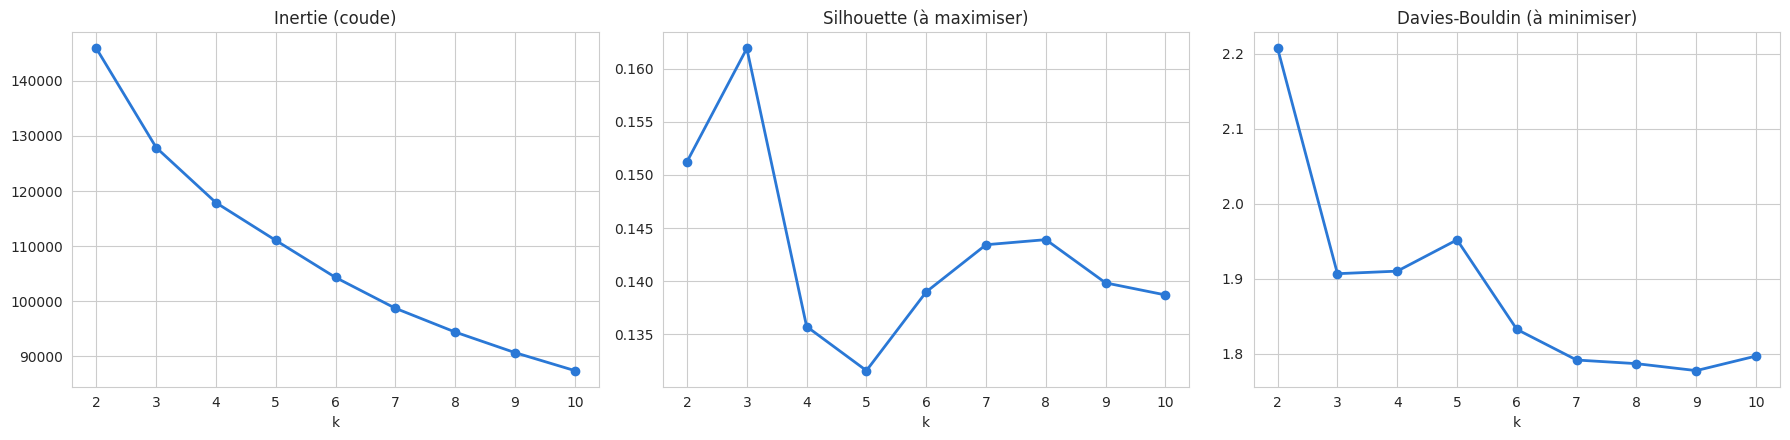

In [16]:
# Les trois critères sous forme de courbes, pour les comparer d'un coup d'oeil
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (nom, vals) in zip(axes, [('Inertie (coude)', inerties), ('Silhouette (à maximiser)', sils), ('Davies-Bouldin (à minimiser)', dbs)]):
    ax.plot(ks, vals, marker='o', color=COULEURS[0], linewidth=2)
    ax.set_title(nom)
    ax.set_xlabel("k")
    ax.set_xticks(ks)
plt.tight_layout()
plt.show()

**Stabilité selon k** : pour chaque k, on relance le K-Means avec 5 graines différentes et on compare les partitions entre elles (ARI, 1 = identiques). On garde le **pire** des 5 résultats : un k pour lequel le découpage change selon le hasard n'est pas fiable.

In [17]:
# Test de stabilité : si on relance le K-Means avec un autre hasard, obtient-on les mêmes groupes ?
stab = []
for k in range(2, 8):
    # Découpage de référence
    ref = KMeans(n_clusters=k, n_init=20, random_state=RS).fit_predict(X)
    # On le compare à 5 autres découpages obtenus avec d'autres graines (ARI = 1 veut dire identiques)
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=5, random_state=s).fit_predict(X)) for s in range(1, 6)]
    stab.append({'k': k, 'ARI min': min(aris), 'ARI moyen': np.mean(aris)})
pd.DataFrame(stab).round(3).set_index('k')

,ARI min,ARI moyen
k,,
2,0.899,0.968
3,0.997,0.998
4,0.661,0.926
5,0.611,0.918
6,0.674,0.927
7,0.756,0.899


**Choix : k = 3.**

- **Silhouette** : maximale pour k = 3 (0.162), puis elle redescend (0.136 pour k = 4).
- **Coude** : l'inertie baisse régulièrement, sans coude net. Ce critère seul ne permet pas de trancher.
- **Davies-Bouldin** : varie peu et sans tendance claire (entre 1.78 et 2.21), donc peu discriminant.
- **Stabilité** : k = 3 est quasi parfaitement reproductible (ARI minimum 0.997). Dès k = 4, le découpage change selon la graine (ARI minimum entre 0.61 et 0.76).

k = 3 est le seul choix à la fois le mieux séparé et reproductible. Les silhouettes restent toutefois faibles (environ 0.16) : les groupes se chevauchent, ce qu'on retrouvera dans l'ACP et dans la conclusion.


# Partie 5 : Modélisation : K-Means

In [18]:
# Nombre de clusters choisi dans la partie précédente
K = 3

# On entraîne le K-Means : il place K centres, rattache chaque personne au centre le plus proche,
# recalcule les centres, et recommence jusqu'à ce que plus rien ne bouge
# n_init=20 : on le lance 20 fois avec des départs différents et on garde le meilleur résultat
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RS).fit(X)

# labels = le numéro de cluster de chaque personne (0, 1 ou 2)
labels = kmeans.labels_
df['cluster'] = labels      # on ajoute ce numéro dans le tableau pour pouvoir analyser les groupes ensuite

print(f"K-Means avec k = {K}")
print(f"Silhouette      : {silhouette_score(X, labels, sample_size=5000, random_state=RS):.3f}")   # séparation des groupes
print(f"Davies-Bouldin  : {davies_bouldin_score(X, labels):.3f}")                                   # ressemblance entre groupes
print()
# Part de la population dans chaque cluster
print("Taille des clusters :")
print(df['cluster'].value_counts(normalize=True).sort_index().round(3))

K-Means avec k = 3


Silhouette      : 0.162
Davies-Bouldin  : 1.906

Taille des clusters :
cluster
0    0.435
1    0.314
2    0.251
Name: proportion, dtype: float64


**Stabilité** : on relance le K-Means avec 5 initialisations différentes. L'ARI (Adjusted Rand Index) compare deux partitions : 1 = identiques. Si l'ARI est proche de 1, les clusters ne dépendent pas du hasard.

In [19]:
# On relance le K-Means 5 fois avec des graines différentes
autres = [KMeans(n_clusters=K, n_init=5, random_state=s).fit_predict(X) for s in [1, 2, 3, 4, 5]]
# On compare chacun au résultat final : plus l'ARI est proche de 1, plus les groupes sont les mêmes
ari_stab = [adjusted_rand_score(labels, a) for a in autres]
print("ARI entre le modèle final et 5 autres graines :", np.round(ari_stab, 3))
print(f"ARI moyen : {np.mean(ari_stab):.3f}")

ARI entre le modèle final et 5 autres graines : [0.997 0.997 0.998 0.999 0.999]
ARI moyen : 0.998


# Partie 6 : Évaluation avec la variable étudiée `marital-status`

Les clusters ont été formés **sans** `marital-status`. On la regarde maintenant pour voir si les groupes la retrouvent.

**Tableau croisé** : pour chaque cluster, la répartition de la situation matrimoniale (chaque ligne somme à 100 %).

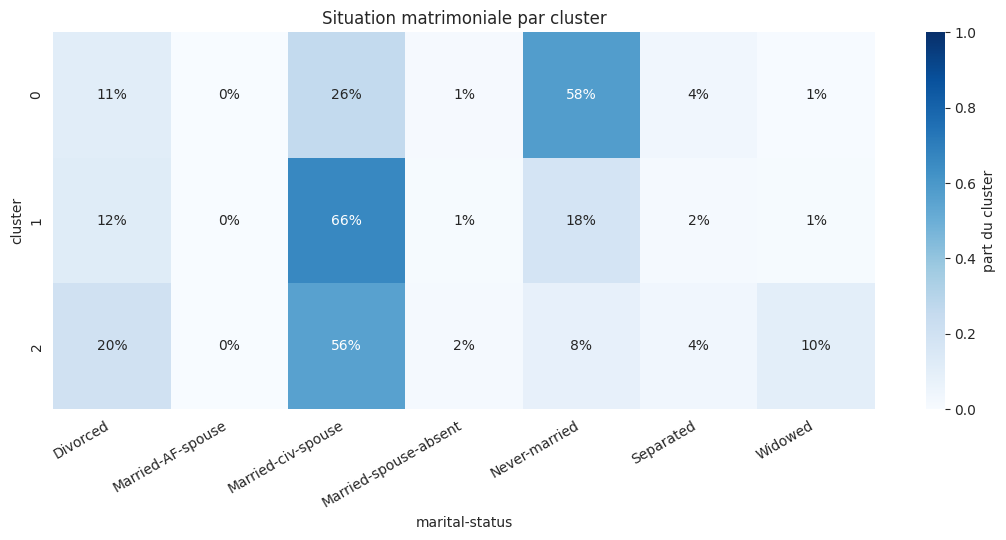

In [20]:
# Tableau croisé : pour chaque cluster (ligne), le pourcentage de chaque situation matrimoniale (colonne)
# normalize='index' : chaque ligne fait 100 %
croise = pd.crosstab(df['cluster'], df['marital-status'], normalize='index')

# Heatmap : plus la case est foncée, plus la part est grande
plt.figure(figsize=(11, 4 + 0.5 * K))
sns.heatmap(croise, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'part du cluster'})
plt.title("Situation matrimoniale par cluster")
plt.xlabel("marital-status")
plt.ylabel("cluster")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Mesures de concordance** entre clusters et `marital-status` :
- **NMI** et **ARI** : 0 = aucun lien, 1 = clusters identiques à la variable.
- **Pureté** : part des individus dont la situation est celle majoritaire dans leur cluster. À comparer à la pureté d'un seul grand cluster (= part de la classe majoritaire).

In [21]:
ms = df['marital-status']                                  # la variable étudiée

# NMI et ARI : deux scores qui mesurent le lien entre les clusters et marital-status (0 = aucun lien, 1 = identiques)
nmi_val = normalized_mutual_info_score(ms, labels)
ari_val = adjusted_rand_score(ms, labels)

# Pureté : dans chaque cluster, on prend la situation la plus fréquente
# et on compte combien de personnes la partagent, puis on divise par le total
purete = pd.crosstab(df['cluster'], ms).max(axis=1).sum() / len(df)

# Point de comparaison : la pureté si tout le monde était dans un seul groupe (= part de la situation la plus fréquente)
base = ms.value_counts(normalize=True).max()

print(f"NMI                       : {nmi_val:.3f}")
print(f"ARI                       : {ari_val:.3f}")
print(f"Pureté des clusters       : {purete:.3f}")
print(f"Pureté sans clustering    : {base:.3f}  (tout le monde dans 'Married-civ-spouse')")

NMI                       : 0.123
ARI                       : 0.132
Pureté des clusters       : 0.598
Pureté sans clustering    : 0.460  (tout le monde dans 'Married-civ-spouse')


**Visualisation en 2 dimensions (ACP)** : on projette les individus sur les deux premiers axes de l'ACP. À gauche, colorés par cluster ; à droite, colorés par situation matrimoniale (regroupée en 3 pour la lisibilité). Si les deux cartes se ressemblent, les clusters retrouvent la situation matrimoniale.

Variance expliquée par les 2 axes : 43.7%


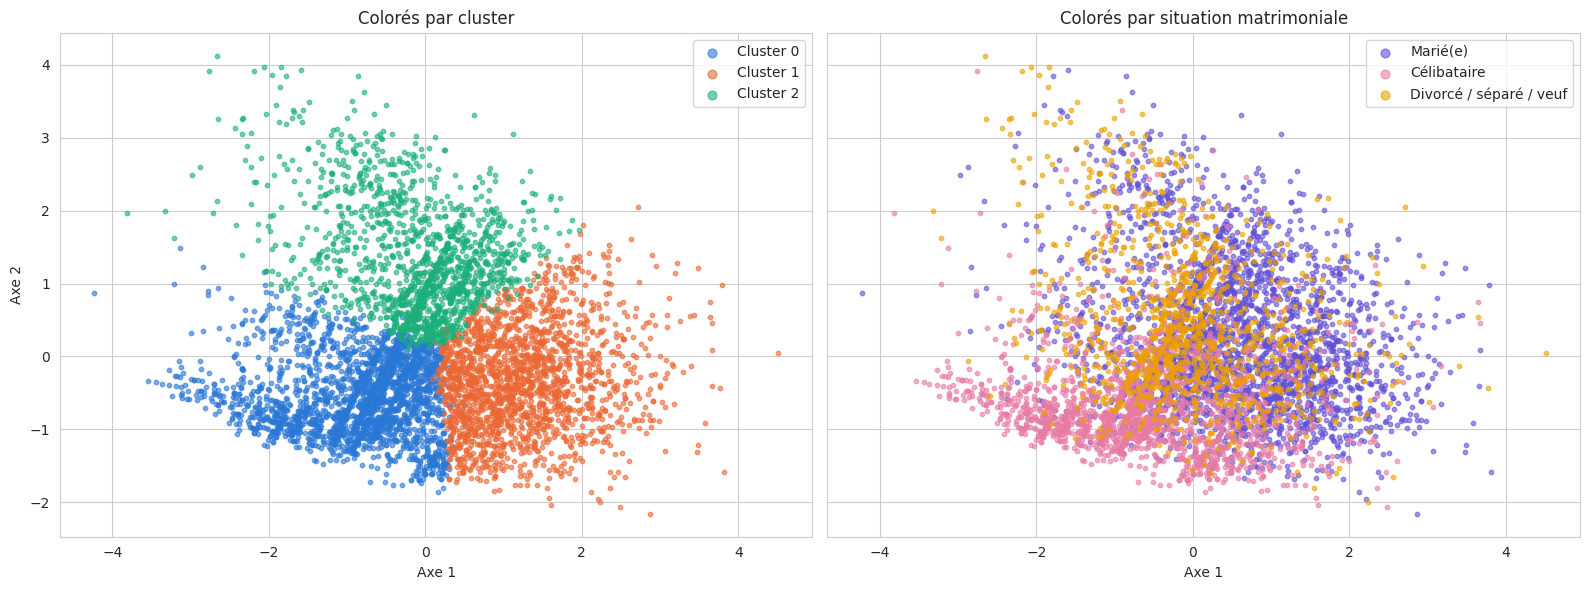

In [22]:
# ACP : on résume les 33 colonnes en 2 axes pour pouvoir dessiner les personnes sur un plan
pca = PCA(n_components=2, random_state=RS)
Z = pca.fit_transform(X)
# Part de l'information gardée par ces 2 axes (le reste est perdu dans le dessin)
print(f"Variance expliquée par les 2 axes : {pca.explained_variance_ratio_.sum():.1%}")

# Pour que le graphique reste lisible, on regroupe les 7 situations matrimoniales en 3 groupes
groupe = ms.map({'Married-civ-spouse': 'Marié(e)', 'Married-AF-spouse': 'Marié(e)', 'Married-spouse-absent': 'Marié(e)',
                 'Never-married': 'Célibataire',
                 'Divorced': 'Divorcé / séparé / veuf', 'Separated': 'Divorcé / séparé / veuf', 'Widowed': 'Divorcé / séparé / veuf'})

# On ne dessine que 6000 personnes tirées au hasard (32 000 points rendraient le graphique illisible)
idx = np.random.RandomState(RS).choice(len(X), 6000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Graphique de gauche : chaque point est coloré selon son cluster
for c in range(K):
    m = labels[idx] == c
    axes[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=10, alpha=0.6, color=COULEURS[c], label=f"Cluster {c}")
axes[0].set_title("Colorés par cluster")
axes[0].legend(markerscale=2)

# Graphique de droite : mêmes points, colorés selon la situation matrimoniale
for i, g in enumerate(['Marié(e)', 'Célibataire', 'Divorcé / séparé / veuf']):
    m = (groupe.values[idx] == g)
    axes[1].scatter(Z[idx][m, 0], Z[idx][m, 1], s=10, alpha=0.6, color=COULEURS_MS[i], label=g)
axes[1].set_title("Colorés par situation matrimoniale")
axes[1].legend(markerscale=2)

for ax in axes:
    ax.set_xlabel("Axe 1")
axes[0].set_ylabel("Axe 2")
plt.tight_layout()
plt.show()

# Partie 7 : Profil de chaque cluster

Résumé de chaque groupe pour lui donner un sens métier.

In [23]:
# Petite fonction : renvoie la valeur la plus fréquente d'une colonne
def mode(s):
    return s.value_counts().index[0]

# Pour chaque cluster, on calcule un résumé : âge moyen, heures, éducation, % d'hommes, % de hauts revenus...
profil = df.groupby('cluster').agg(
    effectif=('age', 'size'),                                          # nombre de personnes
    age_moyen=('age', 'mean'),
    education_moy=('education-num', 'mean'),
    heures_moy=('hours-per-week', 'mean'),
    pct_hommes=('sex', lambda s: (s == 'Male').mean()),                # part d'hommes
    pct_revenu_sup50k=('income', lambda s: (s == '>50K').mean()),      # part de revenus supérieurs à 50 000 $
    pct_gain_capital=('has-capital-gain', 'mean'),                     # part de personnes avec un gain en capital
    workclass_dominant=('workclass', mode),                            # type d'employeur le plus fréquent
    metier_dominant=('occupation', mode),                              # métier le plus fréquent
    situation_dominante=('marital-status', mode),                      # situation matrimoniale la plus fréquente
)
# On transforme le nombre de personnes en part de la population
profil['effectif'] = (profil['effectif'] / len(df)).round(3)
profil = profil.rename(columns={'effectif': 'part_population'})
profil.round(2)

,part_population,age_moyen,education_moy,heures_moy,pct_hommes,pct_revenu_sup50k,pct_gain_capital,workclass_dominant,metier_dominant,situation_dominante
cluster,,,,,,,,,,
0,0.44,27.60,9.36,36.13,0.57,0.04,0.04,Private,Adm-clerical,Never-married
1,0.31,41.57,12.34,48.89,0.81,0.58,0.15,Private,Prof-specialty,Married-civ-spouse
2,0.25,53.69,8.50,37.13,0.66,0.18,0.08,Private,Craft-repair,Married-civ-spouse


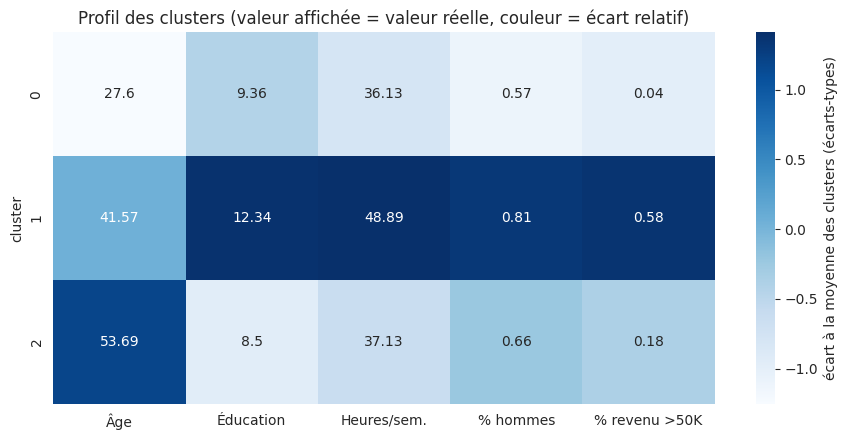

In [24]:
# Heatmap pour comparer les clusters entre eux
# La couleur montre l'écart par rapport à la moyenne des clusters (foncé = valeur haute), et le nombre affiché est la vraie valeur
cols_num = ['age_moyen', 'education_moy', 'heures_moy', 'pct_hommes', 'pct_revenu_sup50k']
noms_aff = ['Âge', 'Éducation', 'Heures/sem.', '% hommes', '% revenu >50K']
# On met toutes les colonnes sur la même échelle pour pouvoir les comparer (centrer-réduire)
z = (profil[cols_num] - profil[cols_num].mean()) / profil[cols_num].std(ddof=0)
z.columns = noms_aff

plt.figure(figsize=(9, 3 + 0.5 * K))
sns.heatmap(z, annot=profil[cols_num].round(2).values, fmt='', cmap='Blues', cbar_kws={'label': 'écart à la moyenne des clusters (écarts-types)'})
plt.title("Profil des clusters (valeur affichée = valeur réelle, couleur = écart relatif)")
plt.ylabel("cluster")
plt.tight_layout()
plt.show()

# Partie 8 : Comparaison avec une CAH (méthode de Ward)

La CAH construit une hiérarchie de regroupements. Elle demande une matrice de distances de taille n x n, impossible sur 32 000 individus : on l'applique à un **échantillon de 3 000 individus**. On compare ensuite son découpage en K groupes à celui du K-Means sur les mêmes individus.

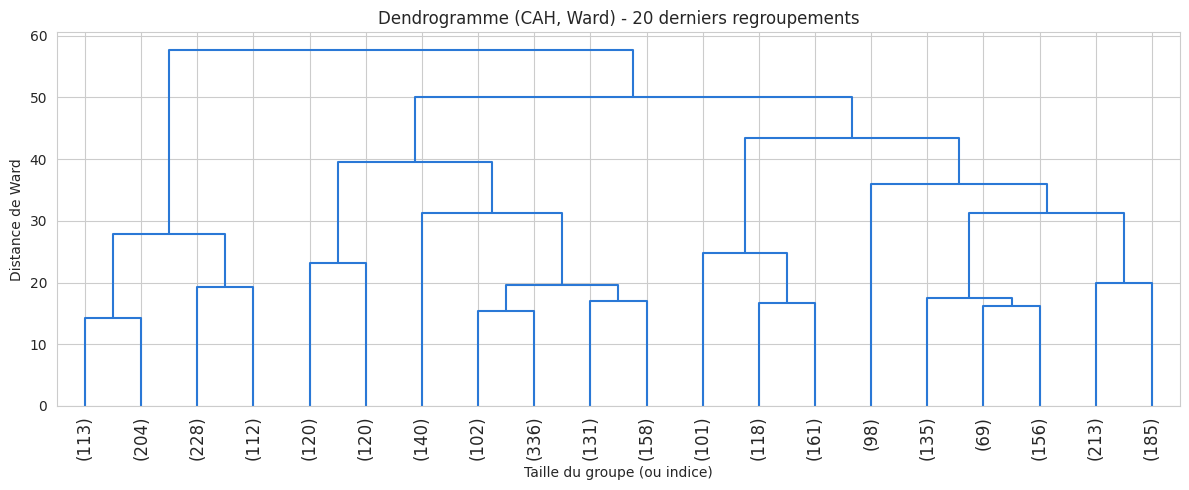

ARI entre CAH et K-Means (sur l'échantillon) : 0.121
NMI CAH vs marital-status                    : 0.136
NMI K-Means vs marital-status (même échant.) : 0.127


In [25]:
# La CAH est trop lourde pour 32 000 personnes : on la fait sur 3000 personnes tirées au hasard
ech = np.random.RandomState(RS).choice(len(X), 3000, replace=False)
Xe = X[ech]

# CAH avec la méthode de Ward : on part de 3000 groupes d'une personne, et on fusionne
# à chaque étape les deux groupes les plus proches, jusqu'à n'en avoir plus qu'un
Z_cah = linkage(Xe, method='ward')

# Dendrogramme : l'arbre de toutes les fusions (on n'affiche que les 20 dernières pour rester lisible)
plt.figure(figsize=(12, 5))
dendrogram(Z_cah, truncate_mode='lastp', p=20, leaf_rotation=90, color_threshold=0, above_threshold_color=COULEURS[0])
plt.title("Dendrogramme (CAH, Ward) - 20 derniers regroupements")
plt.xlabel("Taille du groupe (ou indice)")
plt.ylabel("Distance de Ward")
plt.tight_layout()
plt.show()

# On coupe l'arbre pour obtenir K groupes (comme pour le K-Means)
labels_cah = fcluster(Z_cah, t=K, criterion='maxclust') - 1
# Les groupes du K-Means pour ces mêmes 3000 personnes
labels_km_ech = labels[ech]

# Les deux méthodes donnent-elles les mêmes groupes ? Et laquelle retrouve le mieux marital-status ?
print(f"ARI entre CAH et K-Means (sur l'échantillon) : {adjusted_rand_score(labels_km_ech, labels_cah):.3f}")
print(f"NMI CAH vs marital-status                    : {normalized_mutual_info_score(ms.values[ech], labels_cah):.3f}")
print(f"NMI K-Means vs marital-status (même échant.) : {normalized_mutual_info_score(ms.values[ech], labels_km_ech):.3f}")

# Conclusion

- **Variable étudiée** : `marital-status`, choisie car c'est la variable la mieux retrouvée par un K-Means non supervisé (NMI 0.128, devant `occupation` 0.103). Elle est exclue du clustering, ainsi que `relationship` (quasi-doublon).
- **Pré-traitement** : doublons supprimés, valeurs manquantes -> `Unknown`, `capital-gain` / `capital-loss` transformés en indicateurs binaires, plafonnement doux de `age` et `hours-per-week`, StandardScaler + One-Hot.
- **Modèle** : K-Means avec **k = 3** (meilleure silhouette, découpage très stable), comparé à une CAH de Ward.

**Les 3 profils obtenus**

| Cluster | Part | Profil | Situation matrimoniale |
|---|---|---|---|
| 0 | 44 % | Jeunes (28 ans en moyenne), employés administratifs, 36 h/semaine, 4 % de revenus >50K | 58 % célibataires (contre 33 % dans la population) |
| 1 | 31 % | Professions intellectuelles, diplômés, 42 ans, 49 h/semaine, 58 % de revenus >50K | 66 % mariés |
| 2 | 25 % | Seniors (54 ans), métiers manuels, peu diplômés, 18 % de revenus >50K | 56 % mariés, 20 % divorcés, 10 % veufs (contre 3 % dans la population) |

**La situation matrimoniale est-elle retrouvée ?** Seulement en partie. NMI = 0.123, ARI = 0.132, pureté = 0.598 contre 0.460 pour un groupe unique. Les clusters détectent bien les célibataires (cluster 0) et un peu les veufs et divorcés (cluster 2), mais ils ressemblent surtout à des **étapes de vie et de carrière** (âge, diplôme, revenu) plus qu'à des situations matrimoniales. On ne peut donc pas deviner de façon fiable la situation d'un client à partir de son profil : environ 4 individus sur 10 seraient mal classés.

**Qualité du clustering** : la structure est faible. La silhouette (0.16) est basse, et les 2 premiers axes de l'ACP ne résument que 44 % de la variance. Les profils sont des tendances, pas des groupes nets. La CAH donne un découpage différent (ARI 0.12 avec le K-Means sur l'échantillon) mais un lien comparable avec `marital-status` (NMI 0.136 contre 0.127).

**Limites**
- Données du recensement américain de 1994.
- Le K-Means sur variables One-Hot est une approximation pour des données mixtes (K-Prototypes serait une alternative).
- L'écart entre `marital-status` et `occupation` au screening est modeste.
- Les variables sensibles `race` et `native-country` ont volontairement été laissées de côté ; `sex` est conservée.

Le projet suit la méthodologie CRISP-DM jusqu'à l'étape 5 (Évaluation).
